# Quantum Positional Encodings for Graph Neural Networks — Reproduction

Thabet, Djellabi, Sokolov, Kasture, Henry, Henriet, *Quantum Positional Encodings
for Graph Neural Networks*, ICML 2024, [arXiv:2406.06547](https://arxiv.org/abs/2406.06547).

This notebook walks through the reproduction as a scientific argument: what the
paper claims, how each claim was tested, what the evidence shows, which
alternative explanations were ruled in or out, and where the reproduction stops.

**How it runs.** Everything below executes on a CPU in a few minutes. Two kinds
of evidence appear:

- **live** computations: known-answer checks, the full strongly-regular-graph
  (SRG) protocol on one graph family, the photonic features on that family, and
  the dataset confounder check;
- **stored** results from multi-seed GPU sweeps (NVIDIA L4), loaded from the
  committed `results/` folder. Each stored table names its source file.

Training GRIT on ZINC (hours per run) or the 800-graph synthetic task (four
seeds per encoding) is not repeated here. Small live training runs were tried
and rejected as evidence: with 10 test graphs they are too noisy to support any
conclusion.

Requirements: the paper's `requirements.txt` environment and the SRG catalogs in
`data/QPE_GNN/srg/` (see the README, Data).

## 1. Problem statement and paper claim

Graph transformers need **positional encodings (PEs)**, features that tell each
node where it sits in the graph. The standard choices are Laplacian eigenvectors
(LE) and relative random-walk probabilities (RRWP). The paper proposes PEs
computed from **quantum dynamics** on a Hamiltonian with the graph's topology:

| Encoding | Definition (paper Sec. 3.2) |
|---|---|
| Ising ground-state correlations | eigenvectors of $C_{ij}=\langle Z_iZ_j\rangle$ over the ground states of $H_I=\sum_{(i,j)\in E}Z_iZ_j$ |
| 1-CQRW | $P_t(i,j)=\lvert\langle j\rvert e^{-iH_{XY}t}\lvert i\rangle\rvert^2$ at 20 random times $t\in[0.1,\pi]$ |
| 2-particle walk | occupation correlations of two hard-core particles under the XY Hamiltonian |
| 2-QiRW | powers of the normalised two-particle XY Hamiltonian (classically computable, RRWP-like) |

The paper's main claims, and what would weaken each one in this reproduction:

| ID | Claim | Falsifiable question | Evidence that would weaken it |
|---|---|---|---|
| C1 | Adding 1-CQRW or 2-QiRW to RRWP improves GRIT (Table 1; ZINC MAE 0.060 → 0.058 / 0.059) | Does RRWP + quantum walk give a lower ZINC test MAE than RRWP alone, beyond seed noise? | No separation under a predeclared tie rule, or a width-matched classical control doing as well |
| C2 | Two-particle walk correlations separate same-family SRGs; RRWP provably cannot (Fig. 3, Prop. 4.6) | Does the 2-particle walk separate every non-isomorphic pair while RRWP separates none, with isomorphic copies at distance ≈ 0? | Any unseparated pair, or an isomorphic control above the tolerance |
| C3 | Ising correlations solve a synthetic ladder task at 100% while classical encodings stay at about 45% (Fig. 5) | Does the quantum GCN beat every classical encoding of the same capacity? | A classical feature of the same capacity matching it |

## 2. Data, splits, metrics, and evaluation protocol

| Experiment | Data and split | Metric | Seeds | Budget | Result-scope label |
|---|---|---|---|---|---|
| E1 SRGs (C2) | All 15 `srg(25,12,5,6)` and 10 `srg(26,10,3,4)` graphs (Spence / McKay catalogs); 5 random isomorphic copies per graph | non-isomorphic pairs with sorted-correlation distance > 1e-9; largest isomorphic-copy distance | deterministic (permutation seed 0) | full | **paper-accurate** |
| E2 ladder task (C3) | 800 generated graphs (400 per class, lengths 100-400, 2 crossings), generator seed 314159, split seed 1729 → 640 / 80 / 80 | test accuracy of the best-validation epoch | 0-3 | 200 epochs (paper) | **paper protocol; dataset built from the paper's description** |
| E3 ZINC (C1) | ZINC 12k, official 10,000 / 1,000 / 1,000 split | test MAE of the best-validation epoch | 0-3 | **200 of 2000 epochs** | **partial** |
| Photonic (adaptation) | as E1, and as E3 | as E1, as E3 | as E1, as E3 | as E1, as E3 | **simulated adaptation** (ZINC part also **cross-machine**) |

Every comparison used a **tie rule fixed before the runs**: no winner unless the
mean margin exceeds twice the larger seed standard deviation **and** a paired
test gives p < 0.05. Accuracy uses an exact McNemar test on pooled predictions;
MAE uses a Wilcoxon signed-rank test on seed-averaged per-graph errors. Model
selection uses validation data only; each test split is evaluated once, at the
best-validation epoch.

**Reductions and deviations**, with their likely impact:

| Reduction or deviation | Why | Likely impact |
|---|---|---|
| ZINC trained for 200 of 2000 epochs; schedule compressed | one 2000-epoch run takes about 17 h on an L4 | absolute MAE far above the paper's (≈ +0.03); only relative comparisons are meaningful |
| Table 1: only ZINC (no MNIST, CIFAR10, PATTERN, CLUSTER) | compute budget | C1 tested on one dataset only |
| Ising p=2 SRG parameters unpublished → labelled linked-cluster proxy | not in the paper | the Ising branch of C2 is unresolved |
| Ladder dataset built from App. D.2 prose and Fig. 7 (code unreleased) | no original generator | may differ from the paper's dataset; see Section 9 |
| Ladder task: constant lr 1e-3 (the paper states no schedule); cosine decay kept as a diagnostic | paper-literal reading | decides the RRWP result (Section 9) |
| Dense-batch GRIT (official GRIT is sparse); parameter counts match exactly | dependency-free implementation | possible small numerical differences |
| Photonic features simulated with ideal photons and detectors | no QPU in scope | no hardware claim |
| Photonic ZINC runs on a second machine (CUDA 12.6) and a newer code state | GPU availability; the user accepted the cross-machine comparison | MAE comparison carries a cross-machine label |

In [1]:
import json
import platform
import sys
import time
from importlib import metadata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import torch
from IPython.display import Image, Markdown, display

PAPER_DIR = Path.cwd()
REPO_ROOT = PAPER_DIR.parents[1]
for path in (PAPER_DIR, REPO_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from lib.classical_baseline import degree_one_hot_features
from lib.data import LadderConcatDataset
from lib.photonic import graph_unitary, photonic_cqrw_features, photonic_walk_covariance
from lib.qpe import (
    adjacency_from_edges,
    correlation_matrix_on_state,
    cqrw_features,
    ising_ground_state,
    laplacian_eigenvectors,
    rrwp,
)
from lib.srg import (
    load_srg_catalogs,
    rrwp_correlation,
    sorted_correlation_distance,
    two_particle_walk_correlations,
)
from runtime_lib.data_paths import paper_data_dir

RESULTS = PAPER_DIR / "results"
SRG_DIRECTORY = paper_data_dir("QPE_GNN", ensure_exists=False) / "srg"
NOTEBOOK_START = time.perf_counter()


def load(relative_path):
    return json.loads((RESULTS / relative_path).read_text(encoding="utf-8"))


def candidate(summary, name):
    (record,) = [r for r in summary["candidates"] if r["candidate"] == name]
    return record


def comparison(summary, first, second):
    (record,) = [
        c for c in summary["comparisons"] if {c["a"], c["b"]} == {first, second}
    ]
    return record


COLORS = {
    "quantum": "#4C72B0", "photonic": "#8172B3", "rrwp": "#DD8452",
    "rrwp41": "#C44E52", "laplacian": "#55A868", "degree": "#937860",
    "gcn": "#8C8C8C", "top3": "#64B5CD",
}
print("Python", platform.python_version(), "| torch", torch.__version__,
      "| merlinquantum", metadata.version("merlinquantum"),
      "| perceval", metadata.version("perceval-quandela"))
print("CUDA used in this notebook:", False, "(all live cells run on CPU)")
print("SRG catalogs present:", (SRG_DIRECTORY / "sr251256.g6").is_file())

Python 3.12.3 | torch 2.12.1+cu130 | merlinquantum 0.4.2 | perceval 1.3.1
CUDA used in this notebook: False (all live cells run on CPU)
SRG catalogs present: True


## 3. Minimum mathematics

**Graph Hamiltonians.** For a graph with adjacency $A$, the XY Hamiltonian
$H_{XY}=\sum_{(i,j)\in E}(X_iX_j+Y_iY_j)/2$ conserves the number of excitations.
With one excitation it acts as $2A$ on the $N$ single-site states, so the
single-particle walk is $U(t)=e^{-i\,2A\,t}$. With two excitations it is a walk
of two **hard-core** particles: they hop along edges but never share a node.
This interaction is what makes two-particle statistics informative.

**SRG test (Sec. 4.3).** For a feature matrix $C(G)$, the paper compares graphs
through the sorted entries:
$$d(G_1,G_2)=\tfrac12\sum_k \lvert S(C(G_1))_k-S(C(G_2))_k\rvert .$$
Sorting makes $d$ invariant to node relabelling, so isomorphic copies must give
$d\approx 0$. Two non-isomorphic graphs count as separated if $d>10^{-9}$.

**Why RRWP fails on SRGs (Prop. 4.6).** RRWP stacks powers of the random-walk
matrix $D^{-1}A$. For a strongly regular graph, every power of $A$ is a
combination of $I$, $A$ and $J-I-A$ with coefficients fixed by the parameters
$(n,k,\lambda,\mu)$. Two SRGs with the same parameters therefore have identical
sorted RRWP entries.

**Ising ground-state encoding (ladder task).** Nodes get the leading
eigenvectors of $C_{ij}=\langle\psi_0\rvert Z_iZ_j\lvert\psi_0\rangle$, where
$\psi_0$ is the uniform superposition of all ground states of
$H_I=\sum_{(i,j)\in E}Z_iZ_j$.

**Photonic adaptation (not in the paper).** The same $U(t)$ is a linear-optical
interferometer with one mode per node. $n$ photons injected into distinct modes
interfere, and threshold detectors record which modes clicked. Postselecting
on $n$ clicks plays the role of the hard-core constraint (Section 11).

## 4. Known-answer sanity checks

Each check has an answer known before running it. A failure would invalidate
everything downstream.

In [2]:
checks = {}

# (a) The single-particle propagator is unitary.
cycle_with_chord = adjacency_from_edges(5, [(0, 1), (1, 2), (2, 3), (3, 4), (4, 0), (0, 2)])
unitary = graph_unitary(cycle_with_chord, 0.7)
checks["U(t) unitary"] = np.abs(unitary @ unitary.conj().T - np.eye(5)).max()

# (b) RRWP: channel 0 is the identity, and every row of every channel sums to 1.
random_walk = rrwp(cycle_with_chord, 21)
checks["RRWP channel 0 = identity"] = np.abs(random_walk[0] - np.eye(5)).max()
checks["RRWP rows sum to 1"] = np.abs(random_walk.sum(axis=2) - 1).max()

# (c) One photon in the interferometer is exactly the paper's 1-CQRW.
times = [0.2, 0.7, 1.4]
checks["1 photon = 1-CQRW"] = np.abs(
    photonic_cqrw_features(cycle_with_chord, 1, times) - cqrw_features(cycle_with_chord, 1, times)
).max()

# (d) MerLin and an independent closed form (2x2 permanents) agree for 2 photons.
merlin_cov = photonic_walk_covariance(cycle_with_chord, 0.7, n_photons=2, detection="threshold", backend="merlin")
permanent_cov = photonic_walk_covariance(cycle_with_chord, 0.7, n_photons=2, detection="threshold", backend="permanent")
checks["MerLin = closed form (2 photons)"] = np.abs(merlin_cov - permanent_cov).max()

# (e) Ising ground states of a path (bipartite): the two Neel states, so <Z_i Z_j> = (-1)^distance.
path = nx.path_graph(4)
ising_corr = correlation_matrix_on_state(ising_ground_state(nx.to_numpy_array(path)), 4)
expected = np.array([[(-1) ** abs(i - j) for j in range(4)] for i in range(4)], dtype=float)
checks["Ising path correlations = (-1)^d"] = np.abs(ising_corr - expected).max()

for name, error in checks.items():
    status = "PASS" if error < 1e-10 else "FAIL"
    print(f"{status}  {name:<36s} max error {error:.1e}")
assert all(error < 1e-10 for error in checks.values())

PASS  U(t) unitary                         max error 1.3e-15
PASS  RRWP channel 0 = identity            max error 0.0e+00
PASS  RRWP rows sum to 1                   max error 8.9e-16
PASS  1 photon = 1-CQRW                    max error 0.0e+00
PASS  MerLin = closed form (2 photons)     max error 5.6e-17
PASS  Ising path correlations = (-1)^d     max error 2.2e-16


In [3]:
# (f) The SRG catalogs hold what the paper uses: 15 + 10 graphs, each strongly
# regular with the stated parameters, and pairwise non-isomorphic.
families = load_srg_catalogs(SRG_DIRECTORY)


def srg_parameters(adjacency):
    degrees = adjacency.sum(axis=1)
    squared = adjacency @ adjacency
    lam = {squared[i, j] for i, j in zip(*np.nonzero(adjacency))}
    mu = {squared[i, j] for i, j in zip(*np.nonzero((1 - adjacency) - np.eye(len(adjacency))))}
    assert len(set(degrees)) == len(lam) == len(mu) == 1
    return int(len(adjacency)), int(degrees[0]), int(lam.pop()), int(mu.pop())


for name, graphs in families.items():
    parameters = {srg_parameters(a) for a in graphs}
    nonisomorphic = all(
        not nx.is_isomorphic(nx.from_numpy_array(a), nx.from_numpy_array(b))
        for a, b in combinations(graphs, 2)
    )
    print(f"{name}: {len(graphs)} graphs, parameters {parameters}, pairwise non-isomorphic: {nonisomorphic}")

srg(25,12,5,6): 15 graphs, parameters {(25, 12, 5, 6)}, pairwise non-isomorphic: True


srg(26,10,3,4): 10 graphs, parameters {(26, 10, 3, 4)}, pairwise non-isomorphic: True


**Observation.** All six checks hold to machine precision, and the catalogs
contain exactly the paper's 15 + 10 pairwise non-isomorphic SRGs.
**Inference.** The walk propagator, RRWP, the 1-CQRW and photonic equivalence,
the MerLin simulation and the Ising ground-state construction behave as defined.
**Remaining uncertainty.** These checks validate components, not the end-to-end
claims.

## 5. Pipeline walkthrough

**Positional encodings for GRIT (C1).** For each graph, GRIT receives a stack of
$N\times N$ channels per node pair: 21 RRWP steps, optionally followed by 20
quantum channels (1-CQRW at 20 random times, 2-QiRW powers, or the photonic
covariance). Concatenating 20 quantum channels adds 2,560 parameters
(473,473 → 476,033). The `rrwp41` control instead adds 20 more RRWP steps, so
it matches the input width exactly.

In [4]:
molecule_like = nx.Graph([(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0), (2, 6), (6, 7)])
adjacency = nx.to_numpy_array(molecule_like)
rng = np.random.default_rng(0)
cqrw_times = rng.uniform(0.1, np.pi, 20)          # the paper's random 1-CQRW times
rrwp_channels = rrwp(adjacency, 21)
quantum_channels = cqrw_features(adjacency, 1, cqrw_times)
pe = np.concatenate([rrwp_channels, quantum_channels])
print("RRWP channels       :", rrwp_channels.shape)
print("1-CQRW channels     :", quantum_channels.shape)
print("GRIT pair encoding  :", pe.shape, "(41 channels per node pair)")

zinc = load("zinc_reduced/sweep_summary.json")
for name in ("zinc_rrwp", "zinc_rrwp41", "zinc_cqrw1", "zinc_qirw2"):
    print(f"  {name:<12s} parameters (from run artifacts): {candidate(zinc, name)['num_params']:,}")

RRWP channels       : (21, 8, 8)
1-CQRW channels     : (20, 8, 8)
GRIT pair encoding  : (41, 8, 8) (41 channels per node pair)
  zinc_rrwp    parameters (from run artifacts): 473,473
  zinc_rrwp41  parameters (from run artifacts): 476,033
  zinc_cqrw1   parameters (from run artifacts): 476,033
  zinc_qirw2   parameters (from run artifacts): 476,033


**Node features for the ladder task (C3).** The GCN gets 20 input channels per
node. Each encoding fills them differently, and every model has exactly 3,906
parameters:

- Ising correlation eigenvectors (quantum);
- normalised-Laplacian eigenvectors;
- one-hot node degree (the Phase 5 control).

One paper-length ladder graph is shown below.

synthetic_quantum    parameters: 3,906
synthetic_laplacian  parameters: 3,906
synthetic_degree     parameters: 3,906
synthetic_gcn        parameters: 3,298
synthetic_rrwp       parameters: 7,074


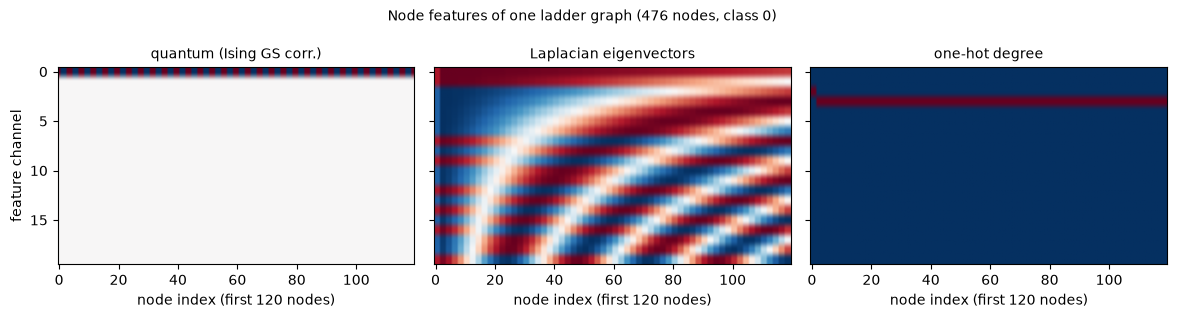

In [5]:
ladder = LadderConcatDataset(per_class=1, length_range=(120, 120), seed=314159,
                             node_encoding="quantum", pe_dim=20, crossing_range=(2, 2)).records[0]
ladder_adjacency = nx.to_numpy_array(nx.Graph(ladder.edges), nodelist=range(ladder.num_nodes))
encodings = {
    "quantum (Ising GS corr.)": ladder.node_features.numpy(),
    "Laplacian eigenvectors": laplacian_eigenvectors(ladder_adjacency, 20),
    "one-hot degree": degree_one_hot_features(ladder_adjacency, 20),
}
figure, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for axis, (name, features) in zip(axes, encodings.items()):
    axis.imshow(features[:120].T, aspect="auto", cmap="RdBu_r")
    axis.set_title(name, fontsize=10)
    axis.set_xlabel("node index (first 120 nodes)")
axes[0].set_ylabel("feature channel")
figure.suptitle(f"Node features of one ladder graph ({ladder.num_nodes} nodes, class {ladder.label})", fontsize=10)
figure.tight_layout()
synthetic = load("synthetic_degree_comparison/sweep_summary.json")
for name in ("synthetic_quantum", "synthetic_laplacian", "synthetic_degree", "synthetic_gcn", "synthetic_rrwp"):
    print(f"{name:<20s} parameters: {candidate(synthetic, name)['num_params']:,}")

## 6. Small live experiment: the SRG protocol on one family

This recomputes the paper-accurate protocol live for `srg(26,10,3,4)` (10
graphs, 45 non-isomorphic pairs, 5 isomorphic copies per graph). The setting is
the reproduction config's: $t=1$, 20 RRWP steps, tolerance $10^{-9}$. The live
distances are then compared with the stored run (`results/srg/srg_metrics.json`).

In [6]:
SRG_CONFIG = json.loads((PAPER_DIR / "configs" / "srg_paper_original.json").read_text())
EVOLUTION_TIME = SRG_CONFIG["evolution_time"]
RRWP_STEPS = SRG_CONFIG["rrwp_steps"]
TOLERANCE = SRG_CONFIG["tolerance"]
PERMUTATIONS = SRG_CONFIG["isomorphic_permutations"]
FAMILY = "srg(26,10,3,4)"
graphs = families[FAMILY]


def evaluate(feature_function, seed=0):
    # Pairwise sorted-correlation distances and isomorphic-copy distances.
    features = [feature_function(a) for a in graphs]
    distances = np.zeros((len(graphs), len(graphs)))
    for i, j in combinations(range(len(graphs)), 2):
        distances[i, j] = distances[j, i] = sorted_correlation_distance(features[i], features[j])
    generator = np.random.default_rng(seed)
    controls = []
    for adjacency, feature in zip(graphs, features):
        for _ in range(PERMUTATIONS):
            permutation = generator.permutation(len(adjacency))
            controls.append(sorted_correlation_distance(feature, feature_function(adjacency[np.ix_(permutation, permutation)])))
    upper = distances[np.triu_indices(len(graphs), k=1)]
    return distances, int((upper > TOLERANCE).sum()), len(upper), max(controls)


start = time.perf_counter()
live = {
    "two_particle_xy": evaluate(lambda a: two_particle_walk_correlations(a, EVOLUTION_TIME)),
    "rrwp": evaluate(lambda a: rrwp_correlation(a, RRWP_STEPS)),
}
stored_srg = load("srg/srg_metrics.json")["families"][FAMILY]
print(f"live SRG protocol on {FAMILY}: {time.perf_counter() - start:.0f} s")
for method, (distances, separated, total, control) in live.items():
    stored = np.asarray(stored_srg[method]["distance_matrix"])
    print(f"{method:<16s} separated {separated}/{total}   max isomorphic-copy distance {control:.1e}   "
          f"max |live - stored| distance {np.abs(distances - stored).max():.1e}")

live SRG protocol on srg(26,10,3,4): 45 s
two_particle_xy  separated 45/45   max isomorphic-copy distance 2.5e-15   max |live - stored| distance 0.0e+00
rrwp             separated 0/45   max isomorphic-copy distance 5.6e-17   max |live - stored| distance 0.0e+00


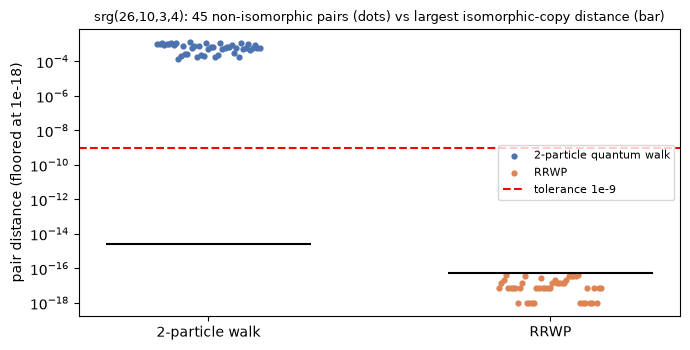

In [7]:
figure, axis = plt.subplots(figsize=(7, 3.6))
for offset, (method, color, label) in enumerate([
        ("two_particle_xy", COLORS["quantum"], "2-particle quantum walk"),
        ("rrwp", COLORS["rrwp"], "RRWP")]):
    distances, _, _, control = live[method]
    upper = distances[np.triu_indices(len(graphs), k=1)]
    axis.scatter(np.full(upper.size, offset) + np.linspace(-0.15, 0.15, upper.size),
                 np.maximum(upper, 1e-18), color=color, s=12, label=label)
    axis.hlines(max(control, 1e-18), offset - 0.3, offset + 0.3, color="black")
axis.axhline(TOLERANCE, color="red", linestyle="--", label="tolerance 1e-9")
axis.set_yscale("log")
axis.set_xticks([0, 1], ["2-particle walk", "RRWP"])
axis.set_ylabel("pair distance (floored at 1e-18)")
axis.set_title(f"{FAMILY}: 45 non-isomorphic pairs (dots) vs largest isomorphic-copy distance (bar)", fontsize=9)
axis.legend(fontsize=8, loc="center right")
figure.tight_layout()

**Observation.** Live, the 2-particle walk separates all 45 pairs: the smallest
pair distance is about $10^{-4}$, while isomorphic copies stay near $10^{-15}$.
RRWP separates none; its pair distances are at the rounding-error level. The
live distances match the stored run.
**Inference.** For this family the paper's Fig. 3 and Prop. 4.6 reproduce
exactly. Section 7 shows the other family from the stored run.
**Remaining uncertainty.** The distance threshold matters only through the
gap between about $10^{-4}$ and about $10^{-15}$, which is eleven orders of
magnitude.
**Claim impact (C2).** Reproduced for the 2-particle walk against RRWP.

## 7. Headline reproduction results

All values are read from committed summaries. The ZINC rows are **partial**
(10% of the paper's training budget).

In [8]:
srg_metrics = load("srg/srg_metrics.json")["families"]
synthetic_lr = load("synthetic_d2_lr_sensitivity/sweep_summary.json")
rows = []
for family, result in srg_metrics.items():
    rows.append((f"Fig. 3, {family}, 2-particle walk", "C2", "all pairs",
                 f"{result['two_particle_xy']['distinguished_pairs']}/{result['two_particle_xy']['total_pairs']}", "1 (det.)"))
    rows.append((f"Prop. 4.6, {family}, RRWP", "C2", "0 pairs",
                 f"{result['rrwp']['distinguished_pairs']}/{result['rrwp']['total_pairs']}", "1 (det.)"))
for name, label, paper in [("synthetic_quantum", "Fig. 5, GCN + Ising GS correlations", "≈100%"),
                           ("synthetic_laplacian", "Fig. 5, GCN + Laplacian eigenvectors", "≈45%"),
                           ("synthetic_rrwp", "Fig. 5, GatedGCN + RRWP (constant lr)", "≈45%")]:
    r = candidate(synthetic, name)
    rows.append((label, "C3", paper, f"{100 * r['mean']:.1f} ± {100 * r['std']:.1f}%", r["observed_runs"]))
r = candidate(synthetic_lr, "synthetic_rrwp_cosine")
rows.append(("Fig. 5, GatedGCN + RRWP (cosine lr, diagnostic)", "C3", "≈45%", f"{100 * r['mean']:.1f} ± {100 * r['std']:.1f}%", r["observed_runs"]))
for name, label, paper in [("zinc_rrwp", "Table 1, ZINC, GRIT RRWP", "0.060 ± 0.002"),
                           ("zinc_cqrw1", "Table 1, ZINC, GRIT RRWP + 1-CQRW", "0.058 ± 0.002"),
                           ("zinc_qirw2", "Table 1, ZINC, GRIT RRWP + 2-QiRW", "0.059 ± 0.004")]:
    r = candidate(zinc, name)
    rows.append((label + " (partial)", "C1", paper, f"{r['mean']:.4f} ± {r['std']:.4f}", r["observed_runs"]))
table = "| Paper item | Claim | Paper | Reproduced | Seeds |\n|---|---|---|---|---|\n"
table += "\n".join(f"| {a} | {b} | {c} | {d} | {e} |" for a, b, c, d, e in rows)
display(Markdown(table))

| Paper item | Claim | Paper | Reproduced | Seeds |
|---|---|---|---|---|
| Fig. 3, srg(25,12,5,6), 2-particle walk | C2 | all pairs | 105/105 | 1 (det.) |
| Prop. 4.6, srg(25,12,5,6), RRWP | C2 | 0 pairs | 0/105 | 1 (det.) |
| Fig. 3, srg(26,10,3,4), 2-particle walk | C2 | all pairs | 45/45 | 1 (det.) |
| Prop. 4.6, srg(26,10,3,4), RRWP | C2 | 0 pairs | 0/45 | 1 (det.) |
| Fig. 5, GCN + Ising GS correlations | C3 | ≈100% | 100.0 ± 0.0% | 4 |
| Fig. 5, GCN + Laplacian eigenvectors | C3 | ≈45% | 47.5 ± 0.0% | 4 |
| Fig. 5, GatedGCN + RRWP (constant lr) | C3 | ≈45% | 86.9 ± 26.3% | 4 |
| Fig. 5, GatedGCN + RRWP (cosine lr, diagnostic) | C3 | ≈45% | 49.4 ± 3.8% | 4 |
| Table 1, ZINC, GRIT RRWP (partial) | C1 | 0.060 ± 0.002 | 0.0905 ± 0.0098 | 4 |
| Table 1, ZINC, GRIT RRWP + 1-CQRW (partial) | C1 | 0.058 ± 0.002 | 0.0866 ± 0.0050 | 4 |
| Table 1, ZINC, GRIT RRWP + 2-QiRW (partial) | C1 | 0.059 ± 0.004 | 0.0870 ± 0.0052 | 4 |

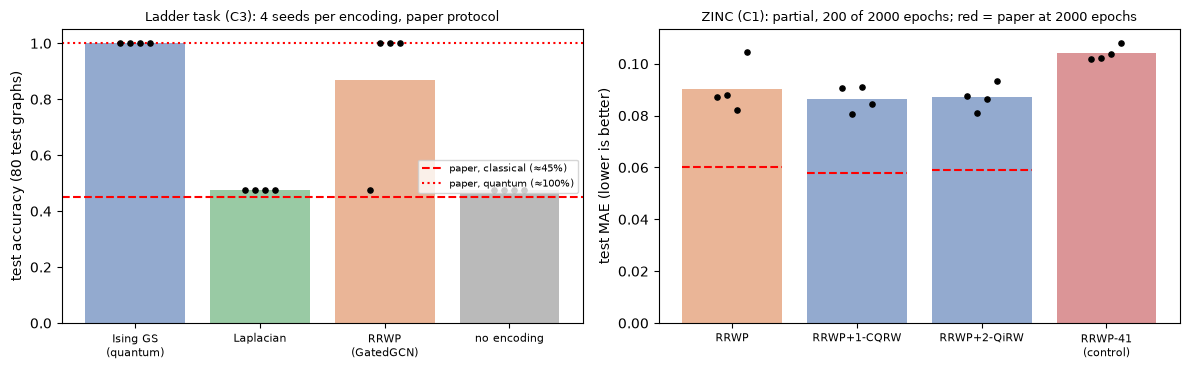

In [9]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
synthetic_systems = [("synthetic_quantum", "quantum", "Ising GS\n(quantum)"), ("synthetic_laplacian", "laplacian", "Laplacian"),
                     ("synthetic_rrwp", "rrwp", "RRWP\n(GatedGCN)"), ("synthetic_gcn", "gcn", "no encoding")]
for x, (name, color, label) in enumerate(synthetic_systems):
    values = np.array(candidate(synthetic, name)["values"])
    left.bar(x, values.mean(), color=COLORS[color], alpha=0.6)
    left.scatter(x + np.linspace(-0.12, 0.12, values.size), values, color="black", s=14, zorder=3)
left.axhline(0.45, color="red", linestyle="--", label="paper, classical (≈45%)")
left.axhline(1.0, color="red", linestyle=":", label="paper, quantum (≈100%)")
left.set_xticks(range(len(synthetic_systems)), [s[2] for s in synthetic_systems], fontsize=8)
left.set_ylabel("test accuracy (80 test graphs)")
left.set_title("Ladder task (C3): 4 seeds per encoding, paper protocol", fontsize=9)
left.legend(fontsize=7, loc="center right")

zinc_systems = [("zinc_rrwp", "rrwp", "RRWP", 0.060), ("zinc_cqrw1", "quantum", "RRWP+1-CQRW", 0.058),
                ("zinc_qirw2", "quantum", "RRWP+2-QiRW", 0.059), ("zinc_rrwp41", "rrwp41", "RRWP-41\n(control)", None)]
for x, (name, color, label, paper) in enumerate(zinc_systems):
    values = np.array(candidate(zinc, name)["values"])
    right.bar(x, values.mean(), color=COLORS[color], alpha=0.6)
    right.scatter(x + np.linspace(-0.12, 0.12, values.size), values, color="black", s=14, zorder=3)
    if paper is not None:
        right.hlines(paper, x - 0.4, x + 0.4, color="red", linestyle="--")
right.set_xticks(range(len(zinc_systems)), [s[2] for s in zinc_systems], fontsize=8)
right.set_ylabel("test MAE (lower is better)")
right.set_title("ZINC (C1): partial, 200 of 2000 epochs; red = paper at 2000 epochs", fontsize=9)
figure.tight_layout()

**Observation.**

- **SRGs:** the 2-particle walk separates 150/150 pairs, RRWP 0/150.
- **Ladder task:** the quantum GCN reaches 100% on every seed. Laplacian
  eigenvectors and no encoding stay at 47.5%, which is always predicting one
  class on this test split. RRWP reaches 100% on three seeds at the paper's
  constant learning rate, but stays at chance under cosine decay.
- **ZINC:** every MAE is about 0.03 above the paper's, and the three encodings
  overlap.

**Inference.** C2 reproduces exactly. The quantum side of C3 reproduces, and so
does the failure of Laplacian eigenvectors. RRWP's failure does not reproduce
robustly (Section 9 explains why). The ZINC numbers cannot match a paper
trained ten times longer (Section 10 shows the models are still
under-trained).

**Remaining uncertainty.** Whether quantum encodings beat a *fair* classical
alternative is the question of Section 8.

**Claim impact.**

- C2: reproduced.
- C3: quantum result reproduced; the classical failure is only partly
  reproduced.
- C1: metric not reproduced (partial budget).

## 8. Fair baseline comparison

A baseline is fair only on the axis the claim is about. The table lists, for
each claim, which dimensions are **matched** and which are not. "Matched" is
used only where the dimension is actually identical.

| Dimension | C1 (ZINC): RRWP+quantum vs RRWP / RRWP-41 | C2 (SRGs): 2-particle walk vs RRWP | C3 (ladder): quantum GCN vs Laplacian / degree GCN |
|---|---|---|---|
| Information and inputs | same graphs; the quantum walk adds 20 channels derived from the same adjacency; RRWP-41 adds 20 RRWP channels instead | same graph, different feature map | same graphs; 20 input channels per node for each (Ising eigenvectors, Laplacian eigenvectors or one-hot degree) |
| Parameter count | matched for RRWP-41 (476,033 each); RRWP alone has 2,560 fewer (473,473) | n/a (no training) | matched: 3,906 for quantum, Laplacian and degree GCNs; RRWP GatedGCN has 7,074; no-encoding GCN 3,298 |
| Training data | matched: 10,000 graphs | n/a | matched: 640 graphs, same split |
| Optimisation steps | matched: 200 epochs, batch 32, same schedule | n/a | matched: 200 epochs, batch 16, Adam lr 1e-3 constant |
| Tuning budget | matched: none (paper hyperparameters) | n/a | matched: none |
| Compute and wall time | similar (4.8 h per run, 4 runs per L4; means within 0.3%) | 2-particle walk is more expensive (eigendecomposition in the 2-particle space) | similar (124-143 s per run on an L4) |
| Evaluation protocol | matched: best-validation epoch, test once, tie rule | matched: same graphs, copies, tolerance | matched: best-validation epoch, test once, tie rule |

The **degree control** was added after Phase 3 found a confounder in this
ladder dataset: node degree alone separates the classes (Section 9). The
comparison plan, including the decision rule, was recorded before the control
was run. Its rule: "the C3 advantage survives if the quantum GCN beats the
degree GCN under the tie rule".

In [10]:
comparison_table = load("comparison/comparison_table.json")
lines = ["| Claim | A | B | Tie-rule verdict | p | Commensurability |", "|---|---|---|---|---|---|"]
for pair in comparison_table["pairwise"]:
    lines.append(f"| {pair['claim']} | {pair['a']} | {pair['b']} | {pair['verdict']} | {pair['p_value']:.2g} | {pair['commensurability']} |")
display(Markdown("\n".join(lines)))

| Claim | A | B | Tie-rule verdict | p | Commensurability |
|---|---|---|---|---|---|
| C1 | zinc_rrwp | zinc_cqrw1 | not distinguishable | 0.014 | COMMENSURABLE |
| C1 | zinc_cqrw1 | zinc_rrwp41 | zinc_cqrw1 better | 0.0029 | COMMENSURABLE |
| C1 | zinc_rrwp | zinc_qirw2 | not distinguishable | 0.43 | COMMENSURABLE |
| C1 | zinc_qirw2 | zinc_rrwp41 | not distinguishable | 0.064 | COMMENSURABLE |
| P2 | zinc_rrwp | zinc_photon2 | not distinguishable | 0.073 | PARTIALLY_COMMENSURABLE |
| P2 | zinc_rrwp41 | zinc_photon2 | zinc_photon2 better | 0.0051 | PARTIALLY_COMMENSURABLE |
| P2 | zinc_cqrw1 | zinc_photon2 | not distinguishable | 0.46 | PARTIALLY_COMMENSURABLE |
| P2 | zinc_qirw2 | zinc_photon2 | not distinguishable | 0.32 | PARTIALLY_COMMENSURABLE |
| C3 | synthetic_quantum | synthetic_degree | not distinguishable | 1 | COMMENSURABLE |
| C3 | synthetic_quantum | synthetic_laplacian | synthetic_quantum better | 5.3e-51 | COMMENSURABLE |
| C3 | synthetic_quantum | synthetic_rrwp | not distinguishable | 4.5e-13 | COMMENSURABLE |
| C3 | synthetic_quantum | synthetic_gcn | synthetic_quantum better | 5.3e-51 | COMMENSURABLE |
| C3 | synthetic_laplacian | synthetic_degree | synthetic_degree better | 5.3e-51 | COMMENSURABLE |
| C3 | synthetic_gcn | synthetic_degree | synthetic_degree better | 5.3e-51 | COMMENSURABLE |

**Observation.**

- **C1:** neither quantum-walk encoding is distinguishable from RRWP. RRWP +
  1-CQRW does beat the width-matched RRWP-41 control (p = 0.003).
- **C3:** the quantum GCN and the degree GCN are indistinguishable. They make
  identical test predictions on every seed (p = 1.0). Both beat Laplacian
  eigenvectors and no encoding.

**Inference.**

- On ZINC at this budget, adding quantum-walk channels is not detectably
  better than RRWP alone. It is better than adding the same number of RRWP
  channels, so the extra channels are not just width.
- On the ladder task, a trivial classical feature of identical capacity
  recovers the quantum result.

**Remaining uncertainty.** The ZINC budget is 10% of the paper's. The ladder
dataset is built from the paper's description, so the paper's own dataset may
not share the degree imbalance.

**Claim impact.**

- C1: comparison unresolved.
- C2: supported.
- C3: comparison unresolved. Not supported on this dataset construction;
  open for the paper's own dataset.

## 9. Controls and ablations

Each control targets one alternative explanation:

| Control | Alternative explanation it tests | Result |
|---|---|---|
| Degree one-hot GCN (C3) | "the ladder classes are separable by a local degree count, so any feature carrying degree solves the task" | see below |
| Top-3 eigenvectors (C3) | "the quantum features work only because they carry rank information (how many eigenvectors are non-zero)" | 98.4% with no rank signal: the quantum features carry the signal themselves |
| Cosine vs constant lr for RRWP (C3) | "the paper's RRWP failure depends on the training schedule" | yes: chance under cosine decay, 3 of 4 seeds solve it at constant lr |
| RRWP-41 (C1) | "quantum channels help only through added width" | 1-CQRW beats RRWP-41; RRWP-41 is the worst system |

First, the confounder itself, measured live on paper-length ladder graphs:

In [11]:
confounder_check = LadderConcatDataset(per_class=6, length_range=(100, 400), seed=314159,
                                       node_encoding="degree", pe_dim=20, crossing_range=(2, 2))
lines = ["| graph | class | nodes | degree-2 nodes | degree-4 nodes |", "|---|---|---|---|---|"]
for index, record in enumerate(confounder_check.records):
    counts = record.node_features.sum(dim=0).numpy()
    lines.append(f"| {index} | {record.label} | {record.num_nodes} | {int(counts[2])} | {int(counts[4])} |")
display(Markdown("\n".join(lines)))

| graph | class | nodes | degree-2 nodes | degree-4 nodes |
|---|---|---|---|---|
| 0 | 1 | 1452 | 3 | 3 |
| 1 | 0 | 724 | 4 | 4 |
| 2 | 0 | 1348 | 4 | 4 |
| 3 | 1 | 764 | 3 | 3 |
| 4 | 1 | 1428 | 3 | 3 |
| 5 | 1 | 988 | 3 | 3 |
| 6 | 0 | 764 | 4 | 4 |
| 7 | 0 | 988 | 4 | 4 |
| 8 | 0 | 1428 | 4 | 4 |
| 9 | 1 | 724 | 3 | 3 |
| 10 | 0 | 1452 | 4 | 4 |
| 11 | 1 | 1348 | 3 | 3 |

quantum vs degree: not distinguishable | McNemar p = 1.0 | discordant predictions: 0


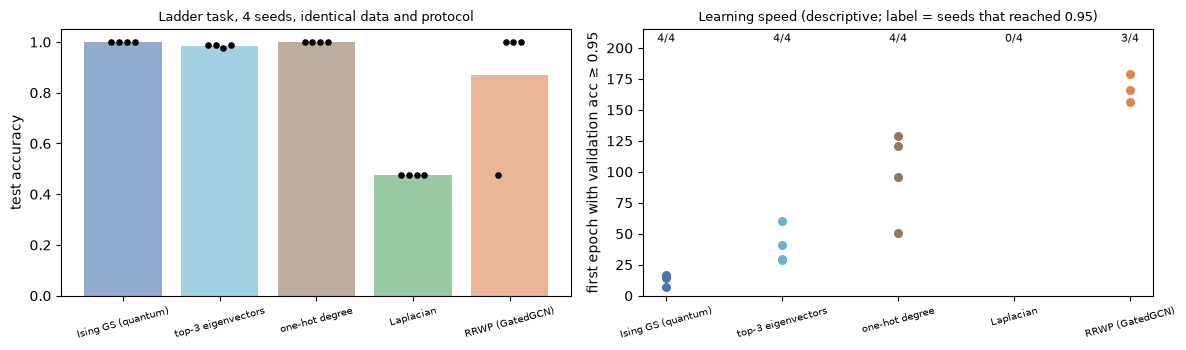

In [12]:
history = load("synthetic_degree_comparison/training_history_summary.json")
crossing = "first_epoch_val_acc_crosses_0.95"
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
systems = [("synthetic_quantum", "quantum", "Ising GS (quantum)"), ("synthetic_quantum_top3", "top3", "top-3 eigenvectors"),
           ("synthetic_degree", "degree", "one-hot degree"), ("synthetic_laplacian", "laplacian", "Laplacian"),
           ("synthetic_rrwp", "rrwp", "RRWP (GatedGCN)")]
for x, (name, color, label) in enumerate(systems):
    values = np.array(candidate(synthetic, name)["values"])
    left.bar(x, values.mean(), color=COLORS[color], alpha=0.6)
    left.scatter(x + np.linspace(-0.12, 0.12, values.size), values, color="black", s=14, zorder=3)
    epochs = [r[crossing] for r in history["runs"] if r["candidate"] == name]
    reached = [e for e in epochs if e is not None]
    right.scatter(np.full(len(reached), x), reached, color=COLORS[color], s=30)
    right.text(x, 205, f"{len(reached)}/4", ha="center", fontsize=8)
left.set_xticks(range(len(systems)), [s[2] for s in systems], fontsize=7, rotation=15)
left.set_ylabel("test accuracy")
left.set_title("Ladder task, 4 seeds, identical data and protocol", fontsize=9)
right.set_xticks(range(len(systems)), [s[2] for s in systems], fontsize=7, rotation=15)
right.set_ylabel("first epoch with validation acc ≥ 0.95")
right.set_ylim(0, 215)
right.set_title("Learning speed (descriptive; label = seeds that reached 0.95)", fontsize=9)
figure.tight_layout()
q_vs_d = comparison(synthetic, "synthetic_quantum", "synthetic_degree")
print("quantum vs degree:", q_vs_d["verdict"], "| McNemar p =", q_vs_d["p_value"],
      "| discordant predictions:", q_vs_d["only_a_correct"] + q_vs_d["only_b_correct"])

**Observation.**

- Every class-0 graph has four degree-2 and four degree-4 nodes; every
  class-1 graph has three of each.
- The degree GCN reaches 100% on all four seeds, with zero discordant
  predictions against the quantum GCN.
- The degree GCN learns more slowly: validation accuracy first reaches 0.95 at
  epochs 51-129, against 7-17 for the quantum encoding.

**Inference.** In this dataset construction the task is solvable from node
degree, and RRWP (whose first step carries degree) solves it too when its
learning rate stays high. The paper's "classical encodings fail" holds for
Laplacian eigenvectors, but not for every classical feature.

**Remaining uncertainty.**

- The paper's generator is unreleased. If its crossings preserve degree
  counts, the confounder would not exist there.
- Learning speed was not a predeclared metric, so it is reported only
  descriptively.

**Claim impact (C3).** The advantage over a fair classical baseline is
unresolved; it is not supported on this construction.

## 10. Robustness and uncertainty

**Seed variability.** Sections 7 and 9 show every seed. On ZINC the seed
spread (0.003-0.010) is larger than the gaps between RRWP, 1-CQRW and 2-QiRW
(≤ 0.004), which is why the tie rule declares no winner. The paper's own ZINC
margins are also inside its stated std.

**Is the ZINC gap under-training or poor generalisation?** The per-run training
histories, exported from the raw runs, answer it:

In [13]:
zinc_history = load("zinc_reduced/training_history_summary.json")
lines = ["| run | best epoch | train MAE at best epoch | best val MAE by epoch 150 | best val MAE by epoch 200 | test MAE |",
         "|---|---|---|---|---|---|"]
for r in zinc_history["runs"]:
    lines.append(f"| {r['run_id']} | {r['best_epoch']} | {r['train_mae_at_best_epoch']:.4f} | "
                 f"{r['best_val_mae_by_epoch_150']:.4f} | {r['best_val_mae']:.4f} | {r['test_mae']:.4f} |")
display(Markdown("\n".join(lines)))
train_at_best = [r["train_mae_at_best_epoch"] for r in zinc_history["runs"]]
improved = sum(r["best_val_mae"] < r["best_val_mae_by_epoch_150"] for r in zinc_history["runs"])
print(f"train MAE at the selected epoch: {min(train_at_best):.3f}-{max(train_at_best):.3f} (paper test MAE: 0.058-0.060)")
print(f"runs whose best validation MAE still improved after epoch 150: {improved}/{len(zinc_history['runs'])}")

| run | best epoch | train MAE at best epoch | best val MAE by epoch 150 | best val MAE by epoch 200 | test MAE |
|---|---|---|---|---|---|
| zinc_cqrw1_seed0 | 181 | 0.0661 | 0.1212 | 0.1084 | 0.0906 |
| zinc_cqrw1_seed1 | 181 | 0.0694 | 0.1186 | 0.1120 | 0.0805 |
| zinc_cqrw1_seed2 | 196 | 0.0696 | 0.1261 | 0.1196 | 0.0909 |
| zinc_cqrw1_seed3 | 192 | 0.0657 | 0.1299 | 0.1194 | 0.0844 |
| zinc_qirw2_seed0 | 181 | 0.0830 | 0.1330 | 0.1220 | 0.0876 |
| zinc_qirw2_seed1 | 187 | 0.0704 | 0.1274 | 0.1183 | 0.0809 |
| zinc_qirw2_seed2 | 190 | 0.0829 | 0.1276 | 0.1235 | 0.0862 |
| zinc_qirw2_seed3 | 169 | 0.0818 | 0.1294 | 0.1251 | 0.0935 |
| zinc_rrwp_seed0 | 198 | 0.0797 | 0.1312 | 0.1223 | 0.0872 |
| zinc_rrwp_seed1 | 159 | 0.0902 | 0.1272 | 0.1230 | 0.0880 |
| zinc_rrwp_seed2 | 183 | 0.0771 | 0.1263 | 0.1165 | 0.0821 |
| zinc_rrwp_seed3 | 180 | 0.0889 | 0.1316 | 0.1246 | 0.1046 |
| zinc_rrwp41_seed0 | 170 | 0.0902 | 0.1295 | 0.1188 | 0.1017 |
| zinc_rrwp41_seed1 | 199 | 0.0855 | 0.1333 | 0.1263 | 0.1024 |
| zinc_rrwp41_seed2 | 193 | 0.0884 | 0.1355 | 0.1284 | 0.1039 |
| zinc_rrwp41_seed3 | 192 | 0.0820 | 0.1312 | 0.1132 | 0.1079 |

train MAE at the selected epoch: 0.066-0.090 (paper test MAE: 0.058-0.060)
runs whose best validation MAE still improved after epoch 150: 16/16


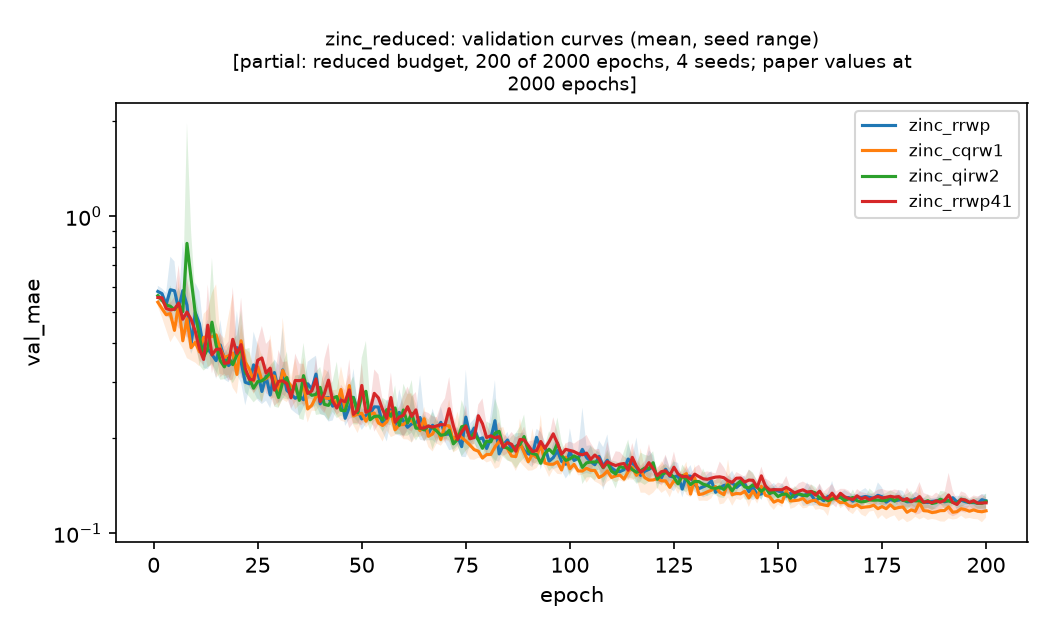

In [14]:
display(Image(filename=str(RESULTS / "zinc_reduced" / "zinc_reduced_validation_curves.png"), width=650))

**Observation.**

- Training MAE at the selected epoch is already above the paper's test MAE.
- Every run was still improving on validation after epoch 150.

**Inference.** The ZINC gap is an optimisation-budget floor, not a
generalisation failure. Absolute agreement would need the full 2000-epoch
budget.

**Remaining uncertainty.** Whether the ties persist at convergence, and
whether dense-batch GRIT matches sparse GRIT at convergence, are both
untested.

**Claim impact (C1).** Unresolved.

## 11. Photonic assessment (MerLin adaptation, not in the paper)

**Translation status: `PARTIAL_MERLIN_TRANSLATION`.**

**Mapping.**
- The interferometer is $U(t)=e^{-i2At}$, the paper's single-particle walk,
  with one optical mode per node.
- $n$ indistinguishable photons are injected into every collision-free set of
  $n$ input modes.
- Threshold detectors record which modes clicked, and only events with exactly
  $n$ clicks are kept (MerLin `ComputationSpace.UNBUNCHED`).
- The feature is the output occupation covariance averaged over inputs: the
  statistic the paper uses for SRGs.

**Why it can work.** Free photons do not interact, and without postselection
their statistics are fixed by the SRG parameters, just like RRWP. Two
ingredients together break this:
- postselection divides by a probability that depends on the input pair;
- bosonic interference couples the four cross relations of input and output
  pairs.

The live ablations below test this.

**Not translated.** The hard-core interaction itself (it would need photon
nonlinearity) and the Ising ground-state task (ground-state preparation is
not an interferometer operation).

In [15]:
start = time.perf_counter()
photonic_live = {
    "photon2_threshold": evaluate(lambda a: photonic_walk_covariance(a, EVOLUTION_TIME, n_photons=2, detection="threshold", backend="merlin")),
    "ablation_photon2_pnr": evaluate(lambda a: photonic_walk_covariance(a, EVOLUTION_TIME, n_photons=2, detection="pnr", backend="merlin")),
    "ablation_photon2_distinguishable": evaluate(lambda a: photonic_walk_covariance(a, EVOLUTION_TIME, n_photons=2, detection="threshold", particles="distinguishable", backend="permanent")),
}
stored_photonic = load("srg_photonic/srg_metrics.json")["families"][FAMILY]
print(f"live photonic SRG on {FAMILY}: {time.perf_counter() - start:.0f} s")
for method, (distances, separated, total, control) in photonic_live.items():
    stored = np.asarray(stored_photonic[method]["distance_matrix"])
    print(f"{method:<34s} separated {separated}/{total}   max isomorphic-copy distance {control:.1e}   "
          f"max |live - stored| {np.abs(distances - stored).max():.1e}")

live photonic SRG on srg(26,10,3,4): 14 s
photon2_threshold                  separated 44/45   max isomorphic-copy distance 2.0e-15   max |live - stored| 0.0e+00
ablation_photon2_pnr               separated 0/45   max isomorphic-copy distance 3.4e-15   max |live - stored| 0.0e+00
ablation_photon2_distinguishable   separated 0/45   max isomorphic-copy distance 1.1e-14   max |live - stored| 0.0e+00


In [16]:
photonic_metrics = load("srg_photonic/srg_metrics.json")["families"]
labels = {"two_particle_xy": "hard-core 2-particle walk (paper reference)", "photon2_threshold": "2 photons, threshold",
          "photon3_threshold": "3 photons, threshold", "ablation_photon1": "1 photon (ablation)",
          "ablation_photon2_pnr": "2 photons, number-resolving, no postselection (ablation)",
          "ablation_photon2_distinguishable": "2 distinguishable photons, postselected (ablation)"}
lines = ["| Method | srg(25,12,5,6) | srg(26,10,3,4) | postselection success | wall-clock |", "|---|---|---|---|---|"]
for method, label in labels.items():
    cells = [f"{photonic_metrics[f][method]['distinguished_pairs']}/{photonic_metrics[f][method]['total_pairs']}" for f in photonic_metrics]
    success = [photonic_metrics[f][method].get("mean_postselection_success") for f in photonic_metrics]
    success_text = " / ".join(f"{s:.3f}" for s in success) if success[0] is not None else "—"
    wall = sum(photonic_metrics[f][method]["wall_clock_s"] for f in photonic_metrics)
    lines.append(f"| {label} | {cells[0]} | {cells[1]} | {success_text} | {wall:.0f} s |")
display(Markdown("Stored full photonic SRG run (`results/srg_photonic/`, MerLin simulator, float64):\n\n" + "\n".join(lines)))

photonic_zinc = load("zinc_photonic/sweep_summary.json")
lines = ["| Encoding | test MAE (4 seeds) | vs RRWP+2 photons |", "|---|---|---|"]
for name, label in [("zinc_photon2", "RRWP + 2 photons (MerLin adaptation)"), ("zinc_cqrw1", "RRWP + 1-CQRW"),
                    ("zinc_qirw2", "RRWP + 2-QiRW"), ("zinc_rrwp", "RRWP"), ("zinc_rrwp41", "RRWP-41")]:
    r = candidate(photonic_zinc, name)
    verdict = "—" if name == "zinc_photon2" else comparison(photonic_zinc, name, "zinc_photon2")["verdict"]
    lines.append(f"| {label} | {r['mean']:.4f} ± {r['std']:.4f} | {verdict} |")
display(Markdown("Stored photonic ZINC comparison (`results/zinc_photonic/`), **partial and cross-machine**:\n\n" + "\n".join(lines)))

Stored full photonic SRG run (`results/srg_photonic/`, MerLin simulator, float64):

| Method | srg(25,12,5,6) | srg(26,10,3,4) | postselection success | wall-clock |
|---|---|---|---|---|
| hard-core 2-particle walk (paper reference) | 105/105 | 45/45 | — | 105 s |
| 2 photons, threshold | 99/105 | 44/45 | 0.920 / 0.923 | 20 s |
| 3 photons, threshold | 105/105 | 45/45 | 0.780 / 0.787 | 754 s |
| 1 photon (ablation) | 0/105 | 0/45 | 1.000 / 1.000 | 1 s |
| 2 photons, number-resolving, no postselection (ablation) | 0/105 | 0/45 | 1.000 / 1.000 | 21 s |
| 2 distinguishable photons, postselected (ablation) | 0/105 | 0/45 | 0.960 / 0.962 | 1 s |

Stored photonic ZINC comparison (`results/zinc_photonic/`), **partial and cross-machine**:

| Encoding | test MAE (4 seeds) | vs RRWP+2 photons |
|---|---|---|
| RRWP + 2 photons (MerLin adaptation) | 0.0842 ± 0.0046 | — |
| RRWP + 1-CQRW | 0.0866 ± 0.0050 | not distinguishable |
| RRWP + 2-QiRW | 0.0870 ± 0.0052 | not distinguishable |
| RRWP | 0.0905 ± 0.0098 | not distinguishable |
| RRWP-41 | 0.1040 ± 0.0028 | zinc_photon2 better |

**Hardware-aware settings** (all simulated, no QPU):

| Field | SRG photonic rows | ZINC `rrwp+photon2` |
|---|---|---|
| Computation space | `UNBUNCHED` (threshold rows); `FOCK` (number-resolving ablation) | `UNBUNCHED` |
| Detector | threshold (number-resolving for one ablation) | threshold |
| Photons / modes | 2 and 3 (1 as ablation) / 25-26 | 2 / atoms per molecule |
| Input state | every collision-free n-mode input | every collision-free pair |
| Postselection | exactly n clicks (success 0.78-0.92) | exactly 2 clicks (success 0.92-0.93) |
| Simulator | MerLin `QuantumLayer`, analytic, float64 | closed-form permanents for all features; MerLin cross-check ≤ 1.1e-16 per run |
| Shots | none (exact probabilities) | none |
| Seeds | deterministic | 0-3 |

**Observation.**

- Live, 2 photons with threshold detection separate 44 of 45 pairs on this
  family. Number-resolving detection without postselection, and
  distinguishable photons, separate none.
- The stored run gives 3 photons 150/150.
- On ZINC the photonic encoding ties with 1-CQRW and 2-QiRW and beats the
  width control.

**Inference.** Postselection plus bosonic interference is enough to recover
the SRG separation that the paper attributes to the particle interaction. It
takes three photons to recover it fully, at about 40× the cost of two.

**Remaining uncertainty.**

- These are ideal-device simulations: loss, partial distinguishability and
  dark counts are not modelled.
- The ZINC comparison mixes machines (accepted by the user), and its budget is
  partial.

**Photonic verdict.** A meaningful partial translation: the SRG claim survives
as an adaptation with 3 photons, and the ZINC encoding performs like the
quantum-walk encodings. No photonic advantage is claimed.

## 12. Claim-level conclusion

Five separate outcomes:

| Outcome | Status | Evidence |
|---|---|---|
| The software executes | yes: live checks, the live SRG protocol and the stored sweeps all complete | Sections 4, 6, 11 |
| The method solves the task | yes for SRGs (150/150) and the ladder task (100%) | Sections 6, 7 |
| The paper's metric reproduces | SRG and ladder (quantum, Laplacian): yes; ZINC: no (partial budget); ladder RRWP: no at constant lr | Section 7 |
| The paper's explanation survives controls | SRG: yes; ladder: no on this dataset (degree confounder) | Section 9 |
| The method beats a fair baseline | SRG: yes (vs RRWP); ZINC: not detectably (ties with RRWP; beats the width control); ladder: no (ties with the degree GCN) | Section 8 |

1. **What reproduced.**
   - The 2-particle quantum walk separates all 150 same-family SRG pairs while
     RRWP separates none (C2; Sections 6-7).
   - The Ising-correlation GCN solves the ladder task on every seed, and
     Laplacian eigenvectors fail as reported (C3, quantum side; Section 7).
2. **What did not reproduce.**
   - ZINC MAE at the paper's level (partial budget; Sections 7, 10).
   - The RRWP failure on the ladder task at the paper's stated constant
     learning rate (Section 9).
3. **What remains unresolved.**
   - Whether quantum-walk encodings improve GRIT on ZINC at the full budget
     (C1; Sections 8, 10).
   - Whether the paper's own ladder dataset lacks the degree confounder
     (C3; Section 9).
   - The exact Ising p=2 SRG result (parameters unpublished).
4. **What was not attempted.** MNIST, CIFAR10, PATTERN and CLUSTER (Table 1);
   ZINC-full and PCQM4Mv2 (Fig. 4); re-deriving the theoretical propositions.
5. **Reproduction verdict: partially reproduced.**
   - C2 reproduced (paper-accurate).
   - C3: quantum result reproduced; the advantage over a fair classical
     baseline is unresolved.
   - C1 partial and unresolved.
   - No quantum advantage is established beyond the SRG expressivity result.
6. **Photonic verdict.** `PARTIAL_MERLIN_TRANSLATION`: 3 photons with threshold
   detection preserve C2 in simulation; the 2-photon ZINC encoding ties with
   the quantum-walk encodings (partial, cross-machine). The paper's
   interacting walk and Ising task have no realistic photonic counterpart
   (Section 11).

In [17]:
print(f"notebook runtime: {time.perf_counter() - NOTEBOOK_START:.0f} s on CPU")

notebook runtime: 78 s on CPU
